# Match simulation demo

Ball-by-ball T20 Monte Carlo simulation (`criiq_models.simulate.engine`), the two genetic-algorithm optimizers (`ga_bowling`, `ga_batting`), and the win-probability chart with key-moments annotation (`keymoments`, `report`).

Re-run after any change to `simulate/*.py` -- like `model_comparison.ipynb`, this is a snapshot of a real run against the live DB, not hardcoded output. Requires data-collection's `criiq.db` and a trained win-probability model (`criiq-data winprob`) for the chosen `(format, gender)`.

In [26]:
%matplotlib inline

from criiq_models.db import connect
from criiq_models.recommend.score import RecommendationScorer
from criiq_models.selection.optimize import select_xi
from criiq_models.features.common import bowling_capable
from criiq_models.features.current import resolve_role
from criiq_models.venues import resolve_venue
from criiq_models.simulate.outcomes import build_outcome_model, build_player_profiles
from criiq_models.simulate.winprob_reader import WinProbLookup
from criiq_models.simulate.engine import simulate_match
from criiq_models.simulate.keymoments import detect_key_moments
from criiq_models.simulate.report import plot_win_probability, aggregate_win_probability
from criiq_models.simulate.scorecard import batting_scorecard, bowling_scorecard, coach_perspective, render_scorecard_text
from criiq_models.simulate.ga_bowling import optimize_bowling_rotation
from criiq_models.simulate.ga_batting import optimize_batting_order
from criiq_models.roster import team_pool

FORMAT, GENDER = "T20", "female"
TEAM1, TEAM2 = "India", "South Africa"
VENUE_NAME = "DY Patil"  # e.g. "Wankhede Stadium" -- conditions batters' setting/chasing strike rate there

# RNG seed for the Monte Carlo simulation and both GAs below. Real cricket
# (and a real Monte Carlo/GA) never repeats itself -- leave this as `None` to
# get a genuinely different match/search every time you run this notebook,
# same as `criiq_models.cli simulate`'s own default. Set a fixed integer only
# if you specifically want to reproduce one exact run again (e.g. to debug a
# particular result).
SEED = None

conn = connect()
VENUE_ID = resolve_venue(conn, VENUE_NAME)[0] if VENUE_NAME else None

## Build two Playing XIs -- the model's own optimal recommendation by default, or your own hand-picked XI

Set `TEAM1_CUSTOM_PLAYERS`/`TEAM2_CUSTOM_PLAYERS` below to a list of player names to override that side's automatic pick with your own choice (mirrors `analyze-xi`'s "coach's own hand-picked XI" idea) -- leave as `None` to use `select_xi`'s provably-optimal XI (the same MILP-based selection `recommend` uses) against the given opponent. Either side can be overridden independently, so you can test "our optimal XI vs a specific opposition XI we name" just as easily as "optimal vs optimal".

In [27]:
# Set either of these to a list of player names to hand-pick that side's XI
# instead of using the model's own optimal recommendation, e.g.:
# TEAM1_CUSTOM_PLAYERS = ["S Mandhana", "Shafali Verma", "D Hemalatha", "JI Rodrigues", "H Kaur",
#                         "S Meghana", "DB Sharma", "P Vastrakar", "YH Bhatia", "M Mani", "N Shree Charani"]
TEAM1_CUSTOM_PLAYERS = None
TEAM2_CUSTOM_PLAYERS = None


def _resolve_name(name):
    matches = [dict(r) for r in conn.execute(
        "SELECT player_id, canonical_name FROM players WHERE canonical_name LIKE ? LIMIT 5",
        (f"%{name}%",)).fetchall()]
    if len(matches) != 1:
        raise ValueError(f"{name!r} resolved to {len(matches)} players: {matches} -- be more specific")
    return matches[0]["player_id"]


def resolve_xi(team_name, opponent_name, custom_players):
    """`custom_players` (list of names) -> that exact XI, in the order given.
    `None` -> the model's own optimal XI (`select_xi`'s provably-optimal MILP
    pick) against `opponent_name`, exactly what `recommend` returns.
    """
    if custom_players:
        if len(custom_players) != 11:
            raise ValueError(f"{team_name}: need exactly 11 players, got {len(custom_players)}")
        return [_resolve_name(n) for n in custom_players], "hand-picked"
    scorer = RecommendationScorer(conn, FORMAT, GENDER)
    pool = scorer.score_many(team_pool(conn, team_name, FORMAT, GENDER), opponent_name)
    xi = select_xi(pool)["xi"]
    return [p["player_id"] for p in xi], "model-optimal"


team1_ids, team1_method = resolve_xi(TEAM1, TEAM2, TEAM1_CUSTOM_PLAYERS)
team2_ids, team2_method = resolve_xi(TEAM2, TEAM1, TEAM2_CUSTOM_PLAYERS)


def bowling_pool(ids):
    return [pid for pid in ids if bowling_capable(resolve_role(conn, pid, FORMAT)[0])]


team1 = {"name": TEAM1, "batting_order": team1_ids, "bowling_pool": bowling_pool(team1_ids)}
team2 = {"name": TEAM2, "batting_order": team2_ids, "bowling_pool": bowling_pool(team2_ids)}


def _name_of(pid):
    row = conn.execute("SELECT canonical_name FROM players WHERE player_id=?", (pid,)).fetchone()
    return dict(row)["canonical_name"] if row else pid


names_preview = {pid: _name_of(pid) for pid in team1_ids + team2_ids}
print(f"{TEAM1} XI ({team1_method}):", [names_preview[p] for p in team1_ids])
print(f"{TEAM2} XI ({team2_method}):", [names_preview[p] for p in team2_ids])
print("bowling-capable:", len(team1["bowling_pool"]), "/", len(team2["bowling_pool"]))

India XI (model-optimal): ['S Mandhana', 'Shafali Verma', 'H Kaur', 'JI Rodrigues', 'S Meghana', 'YH Bhatia', 'DB Sharma', 'AB Kaur', 'D Hemalatha', 'P Vastrakar', 'M Mani']
South Africa XI (model-optimal): ['L Wolvaardt', 'D van Niekerk', 'S Luus', 'A Bosch', 'K Reyneke', 'T Brits', 'M Kapp', 'S Jafta', 'G Jafta', 'L Jones', 'J Winster']
bowling-capable: 8 / 8


## Baseline simulation vs a "player goes out" scenario

In [28]:
outcome_model = build_outcome_model(conn, FORMAT, GENDER, team1_ids, team2_ids)
batter_profiles, bowler_profiles = build_player_profiles(
    conn, FORMAT, team1_ids, team2_ids, TEAM1, TEAM2, venue_id=VENUE_ID)
winprob = WinProbLookup.load(FORMAT, GENDER)

N_REPS = 30
baseline_reps = simulate_match(team1, team2, "team1", outcome_model, batter_profiles, bowler_profiles,
                                winprob, n_reps=N_REPS, rng_seed=SEED)

# Force team1's opener out first ball -- the concrete "what happens if this
# player goes out here" scenario.
forced = {"player_id": team1_ids[0], "over": 0, "ball": 1}
scenario_reps = simulate_match(team1, team2, "team1", outcome_model, batter_profiles, bowler_profiles,
                                winprob, forced_dismissal=forced, n_reps=N_REPS, rng_seed=SEED)

import pandas as pd
pd.Series([r["winner"] for r in baseline_reps]).value_counts(normalize=True) * 100

India           63.333333
South Africa    36.666667
Name: proportion, dtype: float64

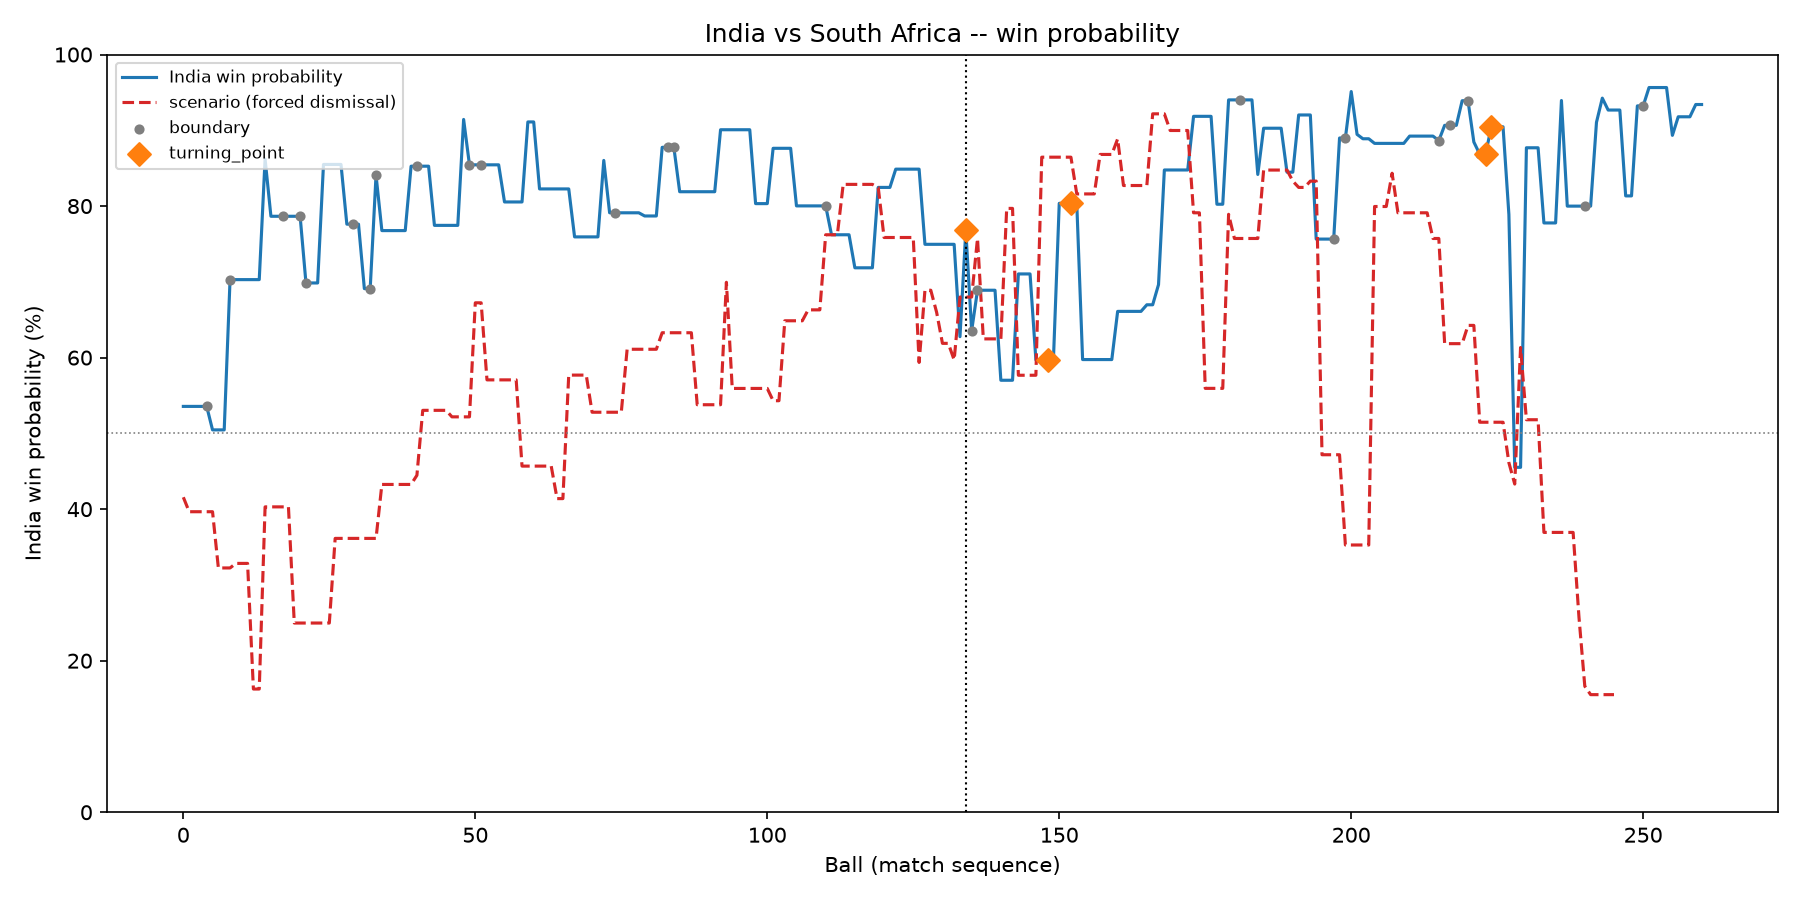

In [29]:
rep = baseline_reps[0]
scenario_rep = scenario_reps[0]
combined_log = pd.concat([rep["first_innings_log"], rep["second_innings_log"]], ignore_index=True)
names = {pid: (conn.execute("SELECT canonical_name FROM players WHERE player_id=?", (pid,)).fetchone() or {"canonical_name": pid})["canonical_name"]
         for pid in team1_ids + team2_ids}
key_moments = detect_key_moments(combined_log, name_map=names)

plot_win_probability(rep, "artifacts/simulation/notebook_demo.png", scenario_rep=scenario_rep, key_moments=key_moments)
from IPython.display import Image
Image("artifacts/simulation/notebook_demo.png")

In [30]:
for m in key_moments:
    print(f"inn{m['innings']} {m['over']}.{m['ball']} -- {m['description']}")

inn1 0.5 -- S Mandhana hits a 4 (score 6/0)
inn1 1.3 -- S Mandhana hits a 4 (score 13/0)
inn1 2.6 -- S Mandhana hits a 4 (score 26/0)
inn1 3.3 -- S Mandhana hits a 4 (score 31/0)
inn1 3.4 -- S Mandhana hits a 4 (score 36/0)
inn1 4.6 -- Shafali Verma hits a 4 (score 44/1)
inn1 5.3 -- H Kaur hits a 4 (score 48/1)
inn1 5.4 -- H Kaur hits a 4 (score 53/1)
inn1 6.5 -- Shafali Verma hits a 4 (score 61/1)
inn1 8.2 -- Shafali Verma hits a 4 (score 67/1)
inn1 8.4 -- Shafali Verma hits a 4 (score 71/1)
inn1 12.3 -- Shafali Verma hits a 4 (score 91/1)
inn1 13.6 -- H Kaur hits a 4 (score 100/1)
inn1 14.1 -- Shafali Verma hits a 4 (score 104/1)
inn1 18.3 -- S Meghana hits a 4 (score 131/3)
inn2 0.1 -- Big swing: 0 by L Wolvaardt off M Mani (-39.5pp win probability)
inn2 0.2 -- L Wolvaardt hits a 4 (score 4/0)
inn2 0.3 -- L Wolvaardt hits a 4 (score 8/0)
inn2 2.3 -- Big swing: wicket by D van Niekerk off M Mani (-20.7pp win probability)
inn2 3.1 -- Big swing: 1 by S Luus off DB Sharma (+20.6pp win p

## Scorecard -- both innings, batting + the opposing bowling figures

Generic by construction (operates purely on the ball log + a name lookup), so this works identically for any two teams/genders `team1`/`team2` above are set to.

In [31]:
first_bat = batting_scorecard(rep["first_innings_log"], names)
first_bowl = bowling_scorecard(rep["first_innings_log"], names)
print(render_scorecard_text(rep["batting_first_team"], first_bat, first_bowl, rep["bowling_first_team"]))

India batting:
  batter                  runs  balls      SR  
  S Mandhana                27     18   150.0  (out)  -- Fastest scoring innings (SR 150.0)
  Shafali Verma             48     51    94.1  (out)  -- Top scorer (48 off 51)
  H Kaur                    27     33    81.8  (out)
  JI Rodrigues              10     10   100.0  (not out)
  S Meghana                 11     10   110.0  (not out)

South Africa bowling:
  bowler                  overs  runs  wkts   econ
  L Jones                   3.0    19     1   6.33
  J Winster                 3.0    36     0  12.00
  G Jafta                   4.0    26     0   6.50
  K Reyneke                 4.0    17     0   4.25  -- Most economical (ER 4.25)
  A Bosch                   1.0     7     0   7.00
  S Luus                    3.0    20     1   6.67
  D van Niekerk             2.0    12     1   6.00  -- Pick of the bowlers (1-for-12)


In [32]:
second_bat = batting_scorecard(rep["second_innings_log"], names)
second_bowl = bowling_scorecard(rep["second_innings_log"], names)
print(render_scorecard_text(rep["bowling_first_team"], second_bat, second_bowl, rep["batting_first_team"]))

South Africa batting:
  batter                  runs  balls      SR  
  L Wolvaardt               18     23    78.3  (out)
  D van Niekerk              3      7    42.9  (out)
  S Luus                    28     26   107.7  (out)
  A Bosch                   10     18    55.6  (out)
  K Reyneke                 36     28   128.6  (out)  -- Top scorer (36 off 28)
  T Brits                    7      8    87.5  (out)
  M Kapp                     9      8   112.5  (not out)
  S Jafta                    3      4    75.0  (not out)

India bowling:
  bowler                  overs  runs  wkts   econ
  M Mani                    3.0    21     1   7.00
  DB Sharma                 4.0    14     1   3.50  -- Most economical (ER 3.5)
  JI Rodrigues              4.0    22     1   5.50
  Shafali Verma             3.0    21     0   7.00
  P Vastrakar               1.0    14     0  14.00
  D Hemalatha               3.0    22     2   7.33  -- Pick of the bowlers (2-for-22)
  H Kaur                    2.0   

## Coach's perspective

Narrated from either named side -- set `COACH_TEAM` to `TEAM1` or `TEAM2`.

In [33]:
COACH_TEAM = TEAM1
print(coach_perspective(rep, key_moments, COACH_TEAM, name_map=names))

India set the total: 140/3 off 20 overs, leaving South Africa to chase 141.
The moment that decided it: Big swing: wicket by S Luus off D Hemalatha (-42.2pp win probability) (innings 2, over 15.1).
Result: A win for India (India won the match).


## Monte Carlo win-probability band across all reps

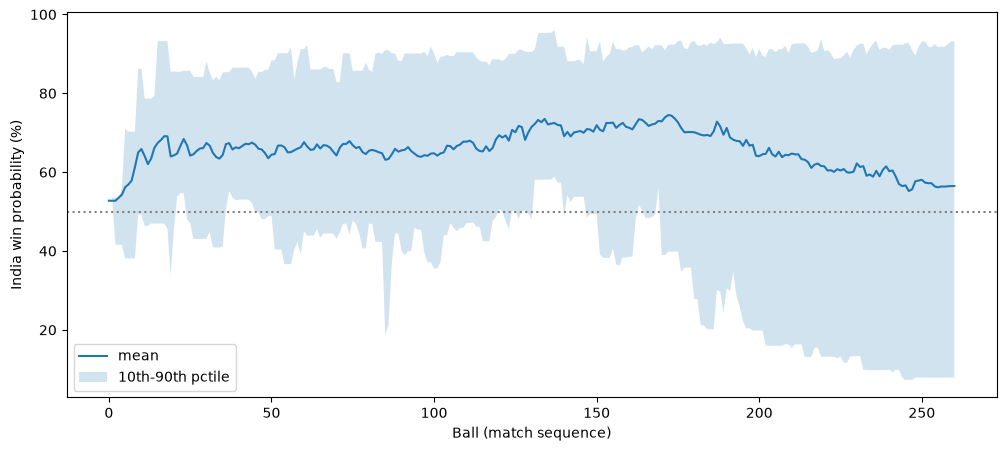

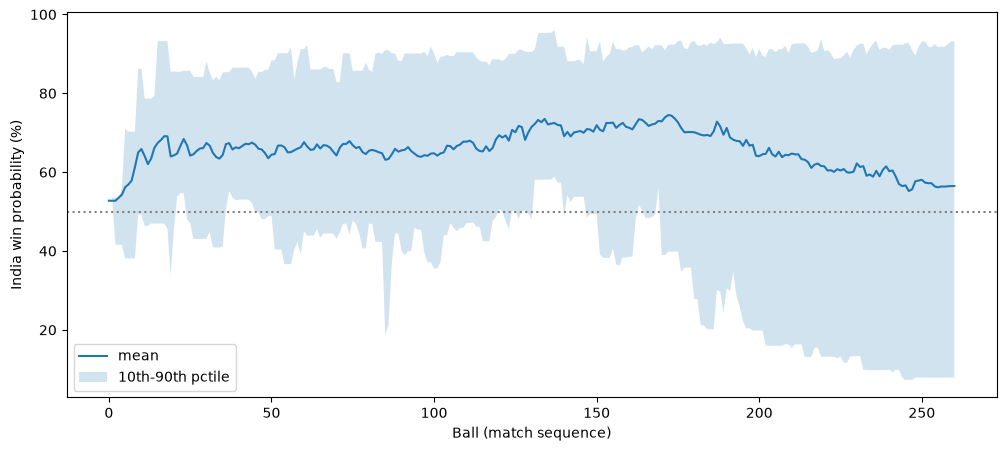

In [34]:
import matplotlib.pyplot as plt

band = aggregate_win_probability(baseline_reps)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(band["match_ball_index"], band["mean"] * 100, label="mean")
ax.fill_between(band["match_ball_index"], band["p10"] * 100, band["p90"] * 100, alpha=0.2, label="10th-90th pctile")
ax.axhline(50, linestyle=":", color="gray")
ax.set_xlabel("Ball (match sequence)")
ax.set_ylabel(f"{team1['name']} win probability (%)")
ax.legend()
fig

## Genetic algorithms: bowling rotation + batting order, with convergence

recognized bowlers (default full quota): ['G Jafta', 'L Jones', 'J Winster', 'D van Niekerk', 'S Luus']
expected runs conceded: 134.9
overs per bowler: {'L Jones': 3, 'S Luus': 4, 'G Jafta': 3, 'J Winster': 3, 'D van Niekerk': 4, 'K Reyneke': 1, 'M Kapp': 1, 'A Bosch': 1}


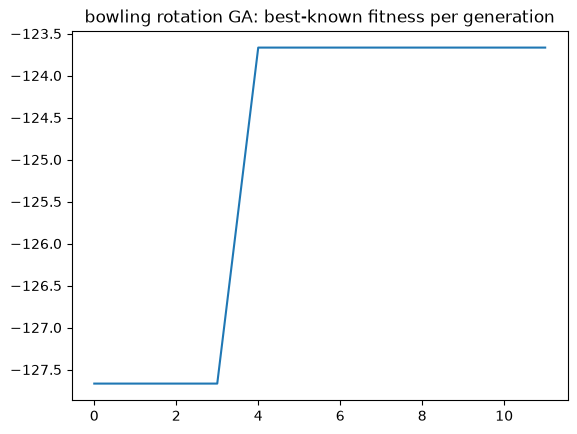

In [35]:
# The up to 5 recognized specialist bowlers (role_bucket == "bowler") default
# to taking the full quota between them, 4 overs each -- real captaincy, not
# an even spread across every bowling-capable player. See ga_bowling.py's
# primary_bowlers docstring for how/when others still get introduced.
def _primary_bowlers(pool):
    specialists = [p for p in pool if resolve_role(conn, p, FORMAT)[0] == "bowler"]
    if len(specialists) >= 5:
        return specialists[:5]
    others = [p for p in pool if p not in specialists]
    return specialists + others[:5 - len(specialists)]

primary_bowlers = _primary_bowlers(team2["bowling_pool"])
print("recognized bowlers (default full quota):", [names_preview.get(b, b) for b in primary_bowlers])

bowling_result = optimize_bowling_rotation(team2["bowling_pool"], team1_ids, outcome_model, batter_profiles,
                                           bowler_profiles, primary_bowlers=primary_bowlers,
                                           pop_size=12, generations=12, n_reps=3, rng_seed=SEED)
print("expected runs conceded:", bowling_result["expected_runs_conceded"])
print("overs per bowler:", {names_preview.get(b, b): n for b, n in bowling_result["overs_per_bowler"].items()})
plt.plot(bowling_result["fitness_history"]); plt.title("bowling rotation GA: best-known fitness per generation"); plt.show()

openers: ['S Mandhana', 'Shafali Verma']
top/middle order: ['JI Rodrigues', 'S Meghana', 'YH Bhatia', 'H Kaur', 'D Hemalatha', 'DB Sharma', 'AB Kaur', 'P Vastrakar']
tail: ['M Mani']
expected score: 133.867
order: ['Shafali Verma', 'S Mandhana', 'P Vastrakar', 'D Hemalatha', 'S Meghana', 'JI Rodrigues', 'AB Kaur', 'H Kaur', 'DB Sharma', 'YH Bhatia', 'M Mani']


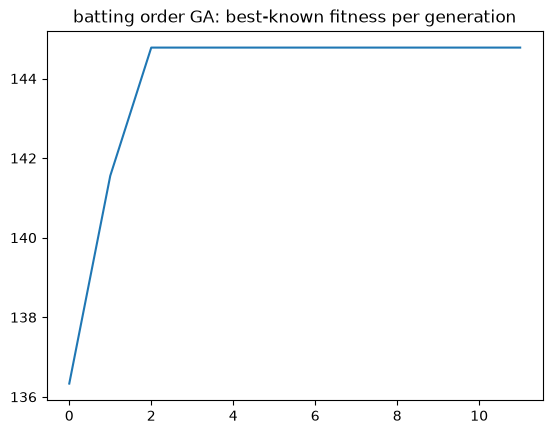

In [36]:
# Batting order is searched in role bands, not one free-for-all permutation:
# openers (can still interchange 1 vs 2), top/middle order (rotate among
# themselves), tail/specialist bowlers (rotate among themselves) -- see
# ga_batting.py's batting_groups docstring.
def _batting_groups(ids):
    rows = [(pid, *resolve_role(conn, pid, FORMAT)) for pid in ids]
    rows.sort(key=lambda r: r[3] if r[3] is not None else float("inf"))
    openers = [r[0] for r in rows[:2]]
    rest = rows[2:]
    tail = [r[0] for r in rest if r[1] == "bowler"]
    top_middle = [r[0] for r in rest if r[1] != "bowler"]
    return [g for g in (openers, top_middle, tail) if g]

batting_groups = _batting_groups(team1_ids)
for label, group in zip(["openers", "top/middle order", "tail"], batting_groups):
    print(f"{label}: {[names_preview.get(p, p) for p in group]}")

batting_result = optimize_batting_order(batting_groups, team2["bowling_pool"], outcome_model, batter_profiles,
                                        bowler_profiles, pop_size=12, generations=12, n_reps=3, rng_seed=SEED)
print("expected score:", batting_result["expected_score"])
print("order:", [names_preview.get(p, p) for p in batting_result["batting_order"]])
plt.plot(batting_result["fitness_history"]); plt.title("batting order GA: best-known fitness per generation"); plt.show()